# Task 2

## Importe

In [25]:
import base_net as bn
import profiles as pr
import weather as wt
import ortsnetz as on
import simulation as sim
from profiles import Lastprofil, Month, DayType, Season
import pandapower as pp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In die Datei `base_net.py` wurden folgende Funktionen ausgelagert:

- `build_base_net()`: erzeugt das Ausgangsnetz (Baseline) und gibt das Netz sowie die Indizes aller Elemente (`idx`) zurück. So startet jeder Test von einem frischen, identischen Netz.
- `vary_parameter(bauteil, parameter, werte, ausgaben)`: ändert einen Parameter eines Bauteils nacheinander auf alle angegebenen Werte, rechnet für jeden Wert einen Lastfluss auf einer frischen Netzkopie, prüft die Konvergenz und gibt die gewünschten Ergebnisse als Tabelle zurück. Der Ausgangswert (Baseline) wird automatisch mitgerechnet und markiert.
- `profiles.py`: liest das BDEW-Standardlastprofil H25 ein (`load_profiles`), erzeugt daraus repräsentative Wochen je Monat (`build_week`: 5 × Werktag, 1 × Samstag, 1 × Sonntag/Feiertag, wahlweise in 15-min- oder Stundenauflösung, mit Dynamisierung) und stellt sie grafisch dar (`plot_week`, `plot_day`, `plot_seasons`). Monate, Tagtypen und Jahreszeiten werden über Enums angesprochen (`Lastprofil.HAUSHALT`, `Month.JULY`, `DayType.WT`, `Season.SUMMER`).
- `weather.py`: ruft stündliche Wetterdaten über die Open-Meteo-API ab (`fetch_weather`), rechnet sie über die Kennlinien in PV- und Windleistung um (`pv_power`, `wind_power`), wählt je Monat eine typische Woche (`select_typical_weeks`) und speichert diese als CSV (`build_weather_weeks`). Im Notebook werden nur die gespeicherten CSV-Dateien geladen (`load_weather_weeks`).
- `ortsnetz.py`: erweitert das bestehende Netz um den Niederspannungsteil des Kerber-Dorfnetzes (`build_ortsnetz`), legt an jeder Leitung zwei Leistungsschalter an, ergänzt optional eine MS-Leitung mit Windenergieanlage und verteilt PV-Anlagen auf die Haushalte (`assign_pv`, `add_pv_systems`).
- `simulation.py`: erstellt die Zeitreihen aller Elemente (`build_timeseries`), prüft sie (`check_timeseries`), rechnet für jeden Zeitschritt einen AC-Lastfluss mit Konvergenzprüfung (`run_simulation`) und wertet die Ergebnisse aus (Tabellen und Diagramme).

## Daten laden

Alle Eingangsdaten liegen im Ordner `data/` und werden hier einmal geladen:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `BDEW_H25_Haushalte.csv` | BDEW-Standardlastprofil H25 (Haushalte), 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `weather_weeks_2025.csv` | je Monat eine typische Wetterwoche (stündlich) mit berechneter PV- und Windleistung |
| | `weather_raw_2025.csv` | Rohdaten des Wetterjahres 2025 (stündlich), Grundlage für `weather_weeks_2025.csv` |

Die Wetterdateien werden einmalig mit `python weather.py` erzeugt (Internetzugang nötig). Fehlen sie, versucht die folgende Zelle den Abruf selbst. Danach rechnet das Notebook ausschließlich mit den gespeicherten Dateien, die Ergebnisse sind damit reproduzierbar.

In [26]:
PROFILES = pr.load_profiles("data")

weather_file = wt.DATA_DIR / f"weather_weeks_{wt.YEAR}.csv"
if not weather_file.exists():
    wt.build_weather_weeks()          # Abruf über die API, benötigt Internet
WEATHER = wt.load_weather_weeks()     # {Month: DataFrame mit 168 Stunden}

# Montag 00:00 jeder Wetterwoche: Last- und Wetterwochen erhalten dieselben Zeitstempel
WEEK_STARTS = {month: df.index[0] for month, df in WEATHER.items()}

print(f"Lastprofil: {PROFILES[Lastprofil.HAUSHALT].shape[0]} Viertelstunden × {PROFILES[Lastprofil.HAUSHALT].shape[1]} Spalten")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

Lastprofil: 96 Viertelstunden × 36 Spalten
Wetter:     12 Wochen × 168 Stunden


## Aufgabe 1

### Aufgabe von Trennschaltern

Kommt noch

### Netzwerk
Externes Netz → Bus 1 (20 kV) → Transformator → Bus 2 (0,4 kV) → Switch → Kabel → Switch → Bus 3 (0,4 kV) → Last

| Komponente | pandapower-Element | Wichtige Daten | Funktion |
|---|---|---|---|
| Externes Netz | `ext_grid` an Bus 1 | `vm_pu` = 1,02, Winkel 0° | Vorgelagertes Mittelspannungsnetz als starre Spannungsquelle. Es ist der Slack-Bus: Er gibt Spannung und Winkelreferenz vor und gleicht die Leistungsbilanz (Last + Verluste) aus. |
| Bus 1 | `bus`, 20 kV | Nennspannung 20 kV | Mittelspannungs-Sammelschiene, Oberspannungsseite des Trafos |
| Transformator | `trafo`, Typ „0.4 MVA 20/0.4 kV“ | S_r = 0,4 MVA, v_k = 6 %, v_kr = 1,425 %, Schaltgruppe Dyn5, Stufensteller ±2 × 2,5 % auf der OS-Seite | Ortsnetztransformator, setzt 20 kV auf 0,4 kV um |
| Bus 2 | `bus`, 0,4 kV | Nennspannung 0,4 kV | Niederspannungs-Sammelschiene der Ortsnetzstation |
| Switch Start | `switch_start` | Leistungsschalter | Leistungsschalter am Anfang des Kabels |
| Kabel | `line`, Typ „NAYY 4x50 SE“ | 0,1 km, r = 0,642 Ω/km, x = 0,083 Ω/km, c = 210 nF/km, I_max = 142 A, 1 System | Niederspannungs-Erdkabel (Aluminium, 50 mm²) zum Verbraucher |
| Switch End | `switch_end` | Leistungsschalter | Leistungsschalter am Ende des Kabels |
| Bus 3 | `bus`, 0,4 kV | Nennspannung 0,4 kV | Netzknoten am Ende des Kabels, Anschlusspunkt des Verbrauchers |
| Last | `load` an Bus 3 | P = 0,05 MW, Q = 0,005 Mvar | Verbraucher als Konstantleistungslast (ZIP-Anteile = 0) |

Das Netz aus Aufgabe 1 wurde volständig übernommen, neu ist nur, das am Anfang und am Ende der Leitung jeweils ein Leistungstrennschalter hinzugefügt wurde.

Beide wurden auf eien Kurzschlussspannung 142 A eingestellt, da dies der maximale Strom durch das Kabel ist.

### Datenstruktur

In [27]:
net, idx = bn.build_base_net()

In [28]:
net.bus

,name,vn_kv,type,zone,in_service,geo
0,Bus 1,20.0,b,None,True,None
1,Bus 2,0.4,b,None,True,None
2,Bus 3,0.4,b,None,True,None


In [29]:
net.trafo

,name,std_type,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,...,tap_step_degree,tap_pos,tap_changer_type,id_characteristic_table,tap_dependency_table,parallel,df,in_service,vector_group,oltc
0,Trafo,0.4 MVA 20/0.4 kV,0,1,0.4,20.0,0.4,6.0,1.425,1.35,...,0.0,0.0,Ratio,<NA>,False,1,1.0,True,Dyn5,False


In [30]:
net.line

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,Line,NAYY 4x50 SE,1,2,0.1,0.642,0.083,210.0,0.0,0.142,1.0,1,cs,True,None


In [31]:
net.load

,name,bus,p_mw,q_mvar,const_z_p_percent,const_i_p_percent,const_z_q_percent,const_i_q_percent,sn_mva,scaling,in_service,type
0,Load,2,0.05,0.005,0.0,0.0,0.0,0.0,NaN,1.0,True,wye


In [32]:
net.switch

,bus,element,et,type,closed,name,z_ohm,in_ka
0,1,0,l,CB,True,CB Line Start,0.0,0.142
1,2,0,l,CB,True,CB Line End,0.0,0.142


### Durchführung

In [33]:
pp.runpp(net)
net.res_bus

,vm_pu,va_degree,p_mw,q_mvar
0,1.020000,0.000000,-0.052513,-0.005511
1,1.017429,-150.405971,0.000000,0.000000
2,0.997047,-150.439166,0.050000,0.005000


In [34]:
net.res_line

,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar,pl_mw,ql_mvar,i_from_ka,i_to_ka,i_ka,vm_from_pu,va_from_degree,vm_to_pu,va_to_degree,loading_percent
0,0.051019,0.005131,-0.05,-0.005,0.001019,0.000131,0.072743,0.072744,0.072744,1.017429,-150.405971,0.997047,-150.439166,51.227854


In [35]:
net.res_trafo

,p_hv_mw,q_hv_mvar,p_lv_mw,q_lv_mvar,pl_mw,ql_mvar,i_hv_ka,i_lv_ka,vm_hv_pu,va_hv_degree,vm_lv_pu,va_lv_degree,loading_percent
0,0.052513,0.005511,-0.051019,-0.005131,0.001494,0.00038,0.001494,0.072743,1.02,0.0,1.017429,-150.405971,12.941537


In [36]:
net.res_load

,p_mw,q_mvar
0,0.05,0.005


In [37]:
net.res_switch

,i_ka,loading_percent,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar
0,0.072744,51.227854,NaN,NaN,NaN,NaN
1,0.072744,51.227854,NaN,NaN,NaN,NaN


#### Auswertung Baseline

| Größe | Wert |
|---|---|
| vm Bus 2 / Bus 3 | 1,0174 pu / 0,9970 pu |
| Spannungsfall Bus 2 → 3 | 0,0204 pu |
| Strom Leitung | 72,7 A |
| Auslastung Leitung / Trafo | 51,2 % / 12,9 % |
| Auslastung Switch Start / End | 51,2 % / 51,2 % |
| Verluste Leitung / Trafo | 1,02 kW / 1,49 kW |

Alle Werte liegen im zulässigen Bereich. Die Trafoverluste sind größer als die Leitungsverluste, weil bei geringer Auslastung die lastunabhängigen **Eisenverluste** (`pfe_kw` = 1,35 kW) dominieren.

## Aufgabe 2 – Transformator und Stufenschalter

### Theorie: Übersetzungsänderung

Ein Transformator überträgt die Spannung im Verhältnis seiner Windungszahlen. Die Übersetzung ist

ü = U_OS / U_US = N_OS / N_US.

Ein **Stufenschalter** verändert über Anzapfungen an einer Wicklung die wirksame Windungszahl und damit die Übersetzung in festen Stufen. Bei der Stufenstellung n und der Stufengröße s (in %) gilt für einen Stufenschalter auf der **Oberspannungsseite**:

ü(n) = ü_N · (1 + n · s/100)  ⇒  u_US ≈ u_OS / (1 + n · s/100)   (in pu, Leerlauf)

- Eine **positive** Stufe schaltet OS-Windungen zu, die Übersetzung wird größer und die US-Spannung **sinkt**.
- Eine **negative** Stufe hebt die US-Spannung an.

Sitzt der Stufenschalter auf der **Unterspannungsseite**, kehrt sich die Wirkrichtung um: ü(n) = ü_N / (1 + n · s/100), eine positive Stufe hebt dann die US-Spannung an. In Verteilnetztransformatoren liegt der Stufenschalter meist auf der OS-Seite, weil dort der Strom kleiner ist und die Anzapfungen leichter zugänglich sind.

**Regelbereich und Stufengröße:** Der Regelbereich ergibt sich aus der Zahl der Stufen und der Stufengröße, hier ±2 × 2,5 % = ±5 %. Kleine Stufen erlauben eine feinere Einstellung, große Stufen einen größeren Bereich bei gleicher Stufenzahl. Die Stufengröße bestimmt außerdem, wie breit das Totband eines Reglers mindestens sein muss, damit er nicht ständig hin- und herschaltet.

**Anzapfung ohne Last (Umsteller) vs. Laststufenschalter (OLTC):**

| | Umsteller / spannungslos verstellbar | Laststufenschalter (OLTC) |
|---|---|---|
| Umschalten | nur im freigeschalteten Zustand | unter Last, ohne Versorgungsunterbrechung |
| Aufbau | einfache Anzapfungen, manuell | Lastumschalter mit Übergangswiderständen oder -drosseln, Motorantrieb, Spannungsregler |
| Typischer Einsatz | klassischer Ortsnetztransformator, Anpassung bei Inbetriebnahme oder saisonal | HS/MS-Umspanntransformatoren, regelbare Ortsnetztransformatoren (rONT) |
| Schalthäufigkeit | selten (wenige Male pro Jahr) | häufig (automatische Regelung) |

*Quellen ergänzen: Fachbuch zu Transformatoren bzw. elektrischen Energieversorgungsnetzen mit Kapitel und Seiten.*

### Stufenschalter im Modell

Der Transformator vom Typ „0.4 MVA 20/0.4 kV“ besitzt in der pandapower-Standardbibliothek bereits einen Stufenschalter. Seine Parameter:

In [38]:
net, idx = bn.build_base_net()
tap_cols = ["tap_side", "tap_neutral", "tap_min", "tap_max", "tap_step_percent",
            "tap_step_degree", "tap_changer_type", "tap_pos", "oltc"]
net.trafo.loc[[idx["trafo"]], tap_cols].T

,0
tap_side,hv
tap_neutral,0.0
tap_min,-2.0
tap_max,2.0
tap_step_percent,2.5
tap_step_degree,0.0
tap_changer_type,Ratio
tap_pos,0.0
oltc,False


| Parameter | Wert | Einheit | Bedeutung |
|---|---|---|---|
| `tap_side` | hv | – | Regelseite: Oberspannungswicklung (20 kV) |
| `tap_neutral` | 0 | – | Neutralstellung, bei der die Nennübersetzung 20 kV / 0,4 kV gilt |
| `tap_min` / `tap_max` | −2 / +2 | – | zulässige Stufenpositionen (5 Stellungen) |
| `tap_step_percent` | 2,5 | % | Spannungsänderung je Stufe, bezogen auf die Bemessungsspannung der Regelseite |
| `tap_step_degree` | 0 | ° | keine Phasendrehung je Stufe |
| `tap_changer_type` | Ratio | – | Längsregler: ändert nur den Betrag der Übersetzung |
| `tap_pos` | 0 | – | aktuelle Stellung (Baseline: Neutralstellung) |
| `oltc` | False | – | **kein** Laststufenschalter: nur spannungslos verstellbar |

Daraus folgt ein **Regelbereich von ±5 %** (ü zwischen 0,95 · ü_N und 1,05 · ü_N). Das ist typisch für einen klassischen Ortsnetztransformator mit Umsteller. Die Parameter passen zum gewählten Gerät und werden daher nicht verändert.

Für die Untersuchung in Aufgabe 5 bedeutet `oltc = False`: Eine realistische Nachbildung ist eine **saisonal** angepasste, feste Stufenstellung. Eine Regelung im Viertelstundentakt setzt einen Laststufenschalter (rONT) voraus.

### Simulation: Variation der Tap-Position

Gegenüber der Baseline wird **nur** `tap_pos` geändert, und zwar auf alle zulässigen Stellungen von −2 bis +2. Jeder Rechenpunkt startet mit `vary_parameter()` von einem frischen Ausgangsnetz, die Konvergenz wird für jeden Fall geprüft.

Zusätzlich wird derselbe Durchlauf **im Leerlauf** (Last außer Betrieb) gerechnet. Dann fließt praktisch kein Strom, es gibt keinen Spannungsfall, und die Spannung an Bus 2 hängt nur von der Übersetzung ab. So lässt sich die Simulation direkt mit der Theorie vergleichen.

In [39]:
TAP_OUTPUTS = [
    ["res_bus.vm_pu.bus1",              "vm Bus 1 [pu]"],
    ["res_bus.vm_pu.bus2",              "vm Bus 2 [pu]"],
    ["res_bus.vm_pu.bus3",              "vm Bus 3 [pu]"],
    ["res_line.i_ka.line",              "I Leitung [kA]"],
    ["res_line.loading_percent.line",   "Auslastung Leitung [%]"],
    ["res_trafo.loading_percent.trafo", "Auslastung Trafo [%]"],
]
TAPS = [-2, -1, 1, 2]

# mit Last (Baseline-Betriebspunkt)
df_tap = bn.vary_parameter("trafo", "tap_pos", TAPS, TAP_OUTPUTS)
df_tap["I Leitung [A]"] = df_tap.pop("I Leitung [kA]") * 1000
df_tap["ΔU Bus 2→3 [pu]"] = df_tap["vm Bus 2 [pu]"] - df_tap["vm Bus 3 [pu]"]
df_tap

,trafo.tap_pos,Baseline,konvergiert,vm Bus 1 [pu],vm Bus 2 [pu],vm Bus 3 [pu],Auslastung Leitung [%],Auslastung Trafo [%],I Leitung [A],ΔU Bus 2→3 [pu]
0,-2.0,,True,1.02,1.071248,1.051929,48.555160,12.949737,68.948327,0.019319
1,-1.0,,True,1.02,1.043650,1.023801,49.889175,12.944707,70.842628,0.019850
2,0.0,x,True,1.02,1.017429,0.997047,51.227854,12.941537,72.743553,0.020382
3,1.0,,True,1.02,0.992483,0.971566,52.571358,12.940099,74.651329,0.020917
4,2.0,,True,1.02,0.968722,0.947268,53.919848,13.261627,76.566184,0.021453


In [40]:
def build_no_load_net():
    """Baseline, aber Last außer Betrieb (Leerlauf)."""
    net, idx = bn.build_base_net()
    net.load.at[idx["load"], "in_service"] = False
    return net, idx

df_tap_nl = bn.vary_parameter("trafo", "tap_pos", TAPS,
                              [["res_bus.vm_pu.bus2", "vm Bus 2 Leerlauf [pu]"]],
                              build_fn=build_no_load_net)

# Theorie: u_US = u_OS / (1 + n * s/100)
s = net.trafo.at[idx["trafo"], "tap_step_percent"]
u_os = net.ext_grid.at[idx["ext"], "vm_pu"]
df_tap_nl["Theorie [pu]"] = u_os / (1 + df_tap_nl["trafo.tap_pos"] * s / 100)
df_tap_nl["Abweichung [pu]"] = df_tap_nl["vm Bus 2 Leerlauf [pu]"] - df_tap_nl["Theorie [pu]"]
df_tap_nl

,trafo.tap_pos,Baseline,konvergiert,vm Bus 2 Leerlauf [pu],Theorie [pu],Abweichung [pu]
0,-2.0,,True,1.073659,1.073684,-0.000026
1,-1.0,,True,1.046129,1.046154,-0.000025
2,0.0,x,True,1.019976,1.020000,-0.000024
3,1.0,,True,0.995098,0.995122,-0.000024
4,2.0,,True,0.971405,0.971429,-0.000023


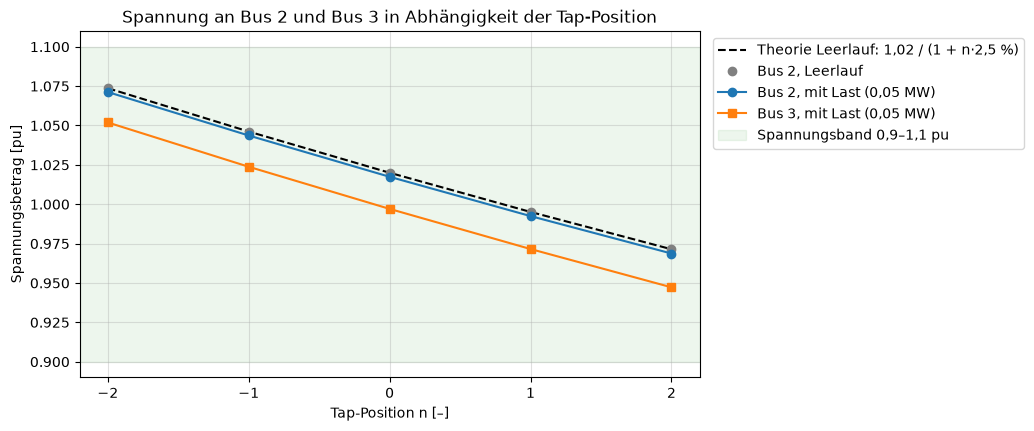

In [41]:
fig, ax = plt.subplots(figsize=(8, 4.5))
taps = df_tap["trafo.tap_pos"]
ax.plot(taps, df_tap_nl["Theorie [pu]"], "k--", label="Theorie Leerlauf: 1,02 / (1 + n·2,5 %)")
ax.plot(taps, df_tap_nl["vm Bus 2 Leerlauf [pu]"], "o", color="grey", label="Bus 2, Leerlauf")
ax.plot(taps, df_tap["vm Bus 2 [pu]"], "o-", label="Bus 2, mit Last (0,05 MW)")
ax.plot(taps, df_tap["vm Bus 3 [pu]"], "s-", label="Bus 3, mit Last (0,05 MW)")
ax.axhspan(0.9, 1.1, color="green", alpha=0.07, label="Spannungsband 0,9–1,1 pu")
ax.set_xticks(taps)
ax.set_xlabel("Tap-Position n [–]")
ax.set_ylabel("Spannungsbetrag [pu]")
ax.set_title("Spannung an Bus 2 und Bus 3 in Abhängigkeit der Tap-Position")
ax.grid(True, alpha=0.4)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### Auswertung

Alle zehn Lastflüsse (mit Last und im Leerlauf) konvergieren.

**Richtung:** Eine höhere Tap-Position senkt die Spannung auf der Unterspannungsseite. Das entspricht der Theorie für einen Stufenschalter auf der OS-Seite: Mehr wirksame OS-Windungen vergrößern die Übersetzung. Bus 1 bleibt als Slack-Bus unverändert bei 1,02 pu.

**Größenordnung:**

| Tap | Theorie (Leerlauf) | Bus 2 Leerlauf | Bus 2 mit Last | Bus 3 mit Last |
|---|---|---|---|---|
| −2 | 1,0737 | 1,0737 | 1,0712 | 1,0519 |
| −1 | 1,0462 | 1,0461 | 1,0437 | 1,0238 |
| 0 | 1,0200 | 1,0200 | 1,0174 | 0,9970 |
| +1 | 0,9951 | 0,9951 | 0,9925 | 0,9716 |
| +2 | 0,9714 | 0,9714 | 0,9687 | 0,9473 |

- Im **Leerlauf** stimmt die Simulation bis auf 0,00003 pu mit u = 1,02 / (1 + n · 0,025) überein. Die kleine Restabweichung stammt vom Leerlaufstrom des Trafos (Magnetisierung, `i0_percent`). Eine Stufe verschiebt die Spannung um etwa 2,4–2,7 %. Der Wert ist nicht exakt symmetrisch, weil die Stufe im Nenner steht: 1/0,975 = 1,0256, aber 1/1,025 = 0,9756.
- **Mit Last** liegt Bus 2 um etwa 0,0026 pu unter dem Leerlaufwert (Spannungsfall über der Trafoimpedanz), Bus 3 zusätzlich um etwa 0,02 pu (Spannungsfall über dem Kabel). Diese Spannungsfälle werden vom Stufenschalter **nicht beeinflusst**: Er verschiebt das gesamte NS-Spannungsniveau parallel.
- Der Spannungsfall Bus 2 → 3 nimmt mit steigender Tap-Position leicht zu (0,0193 → 0,0214 pu), weil die Konstantleistungslast bei niedrigerer Spannung mehr Strom zieht (68,9 A → 76,6 A).

**Spannungsband:** Im aktuellen Betriebspunkt bleiben alle Stellungen im Band 0,9–1,1 pu. Der volle Regelbereich verschiebt Bus 3 zwischen 0,947 und 1,052 pu, also um insgesamt etwa 10 %. Ob das ausreicht, um die saisonalen Schwankungen durch Last und PV auszugleichen, wird in Aufgabe 4 und 5 untersucht.

## Profile und Datengrundlagen

Für die saisonale Untersuchung werden drei Zeitreihen benötigt: der Verbrauch der Haushalte, die Erzeugung von PV-Anlagen und die Erzeugung einer Windenergieanlage. Alle Zeitreihen werden einheitlich aufbereitet:

- **Zeitraum:** je Monat eine Woche (Montag 00:00 bis Sonntag 23:00), also 12 Wochen pro Jahr. Damit sind alle Jahreszeiten und innerhalb jeder Woche die Unterschiede zwischen Werktag und Wochenende abgebildet.
- **Auflösung:** 1 Stunde. Die Wetterdaten liegen nur stündlich vor; das Lastprofil wird deshalb auf Stundenmittelwerte gemittelt. Für die Untersuchung der Spannungshaltung ist das ausreichend, kurzzeitige Spitzen innerhalb einer Stunde werden aber geglättet.
- **Zeitstempel:** lokale Zeit (MEZ/MESZ), jeweils Beginn der Stunde. Last- und Wetterwoche liegen auf denselben Kalendertagen.
- **Jahr:** 2025.

### Lastprofil der Haushalte (BDEW H25)

**Herkunft:** Das Standardlastprofil H25 ist der Nachfolger des Haushaltsprofils H0 aus dem Jahr 1999. Es wurde im Auftrag des BDEW von der BTU EVU Beratung GmbH aus Abrechnungsdaten von 62 Verteilnetzbetreibern der Jahre 2018 und 2019 erstellt [1, S. 3]. Weil zu dieser Zeit bereits PV-Anlagen in Betrieb waren, enthält das Profil einen moderaten PV-Eigenverbrauch [1, S. 3]. Die Daten stammen aus der BDEW-Veröffentlichung der repräsentativen Profile 2025 [2].

**Aufbau der Datei:** 12 Monate × 3 Tagtypen (WT = Werktag, SA = Samstag, FT = Sonn- und Feiertag) mit je 96 Viertelstundenwerten. Die Werte sind Energiemengen in kWh je Viertelstunde, normiert auf einen Jahresverbrauch von 1 Mio. kWh [1, S. 3].

**Aufbereitung:**

1. *Woche bilden:* Montag bis Freitag erhalten den Tagtyp WT, Samstag SA, Sonntag FT. Wochen mit gesetzlichem Feiertag (NRW) werden bei der Auswahl der Wochen ausgeschlossen, damit die Annahme „fünf Werktage“ gilt.
2. *Leistung:* Die Energie einer Viertelstunde wird in die mittlere Leistung umgerechnet: P = E / 0,25 h = 4 · E.
3. *Dynamisierung:* H25 ist „entdynamisiert“; beim Ausrollen ist die Dynamisierungsfunktion anzuwenden [1, S. 3–4]. Sie bildet den Jahresgang des Verbrauchs ab (im Winter höher, im Sommer niedriger):

   F(t) = −3,92·10⁻¹⁰·t⁴ + 3,2·10⁻⁷·t³ − 7,02·10⁻⁵·t² + 2,1·10⁻³·t + 1,24 &nbsp;&nbsp; (t = Tag des Jahres) [3]

   Der Faktor wird auf vier Nachkommastellen gerundet [1, S. 4] und liegt zwischen etwa 0,79 (Juli/August) und 1,26 (Ende Dezember).
4. *Skalierung:* P_Haushalt = P_norm · F(t) · W_a / 1 000 000 kWh mit dem Jahresverbrauch W_a des Haushalts.
5. *Stundenwerte:* Mittelwert der vier Viertelstundenleistungen einer Stunde.

**Vorzeichen und Einheiten:** Die Last wird im Verbraucherzählpfeilsystem angegeben (Bezug positiv), in pandapower in MW (`unit="MW"`). Die Blindleistung ist im Profil nicht enthalten und wird in Aufgabe 3 über einen Leistungsfaktor festgelegt.

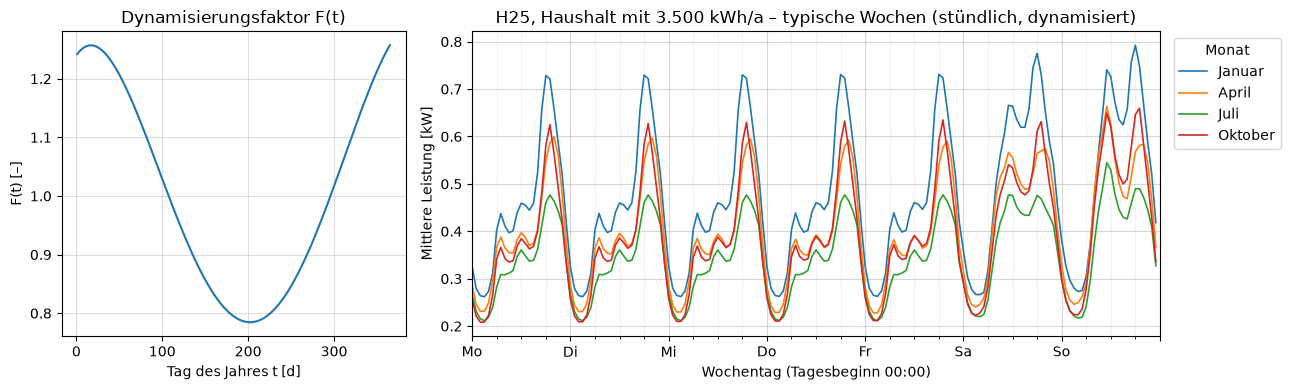

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})

t = np.arange(1, 366)
axes[0].plot(t, pr.dynamization_factor(t))
axes[0].set_title("Dynamisierungsfaktor F(t)")
axes[0].set_xlabel("Tag des Jahres t [d]")
axes[0].set_ylabel("F(t) [–]")
axes[0].grid(True, alpha=0.4)

pr.plot_week(PROFILES, Lastprofil.HAUSHALT,
             months=[Month.JANUARY, Month.APRIL, Month.JULY, Month.OCTOBER],
             annual_kwh=3500, starts=WEEK_STARTS, resolution="1h", ax=axes[1])
axes[1].set_title("H25, Haushalt mit 3.500 kWh/a – typische Wochen (stündlich, dynamisiert)")
fig.tight_layout()
plt.show()

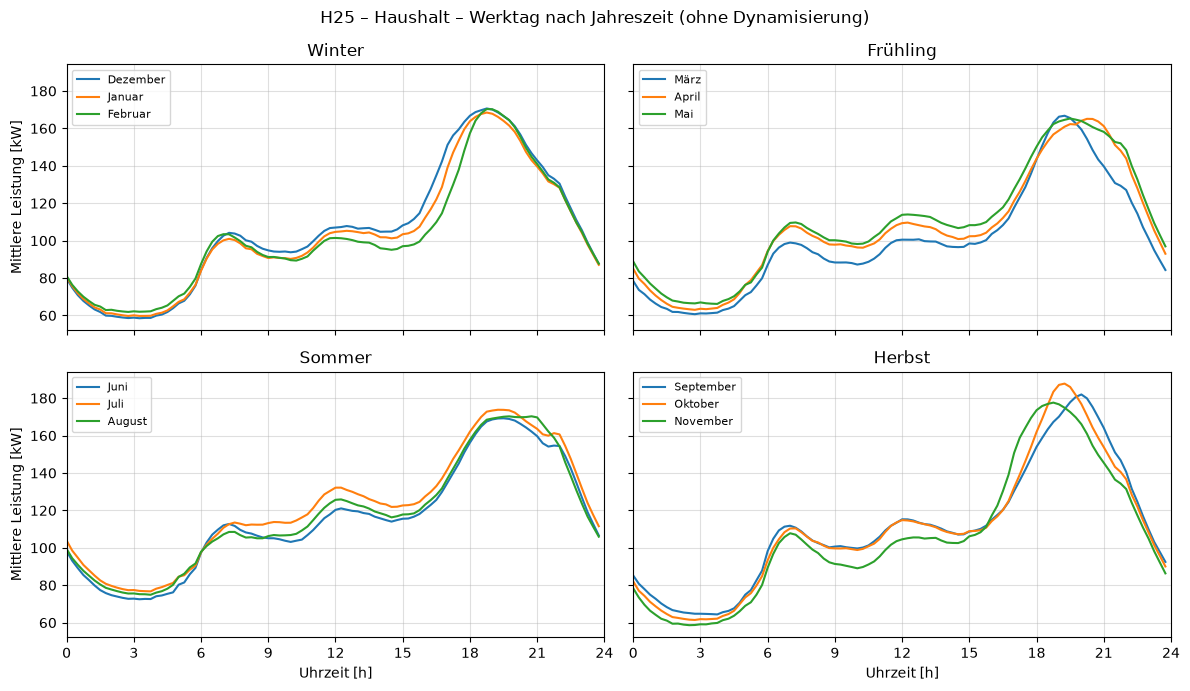

In [43]:
pr.plot_seasons(PROFILES, Lastprofil.HAUSHALT, daytype=DayType.WT)
plt.show()

### Wetterdaten (Open-Meteo)

**Herkunft:** Die Wetterdaten stammen aus der *Historical Weather API* von Open-Meteo [4], [6]. Sie beruht auf Reanalyse-Datensätzen, in denen Messungen von Wetterstationen, Satelliten, Flugzeugen und Bojen mit einem numerischen Wettermodell zu einem lückenlosen Gitterdatensatz verbunden werden, unter anderem ERA5 des europäischen Wetterdienstes ECMWF [5].

**Abruf:** Standort 51,2° N, 7,34° E (Bergisches Land, NRW), Jahr 2025, stündliche Werte:

| Variable | Einheit | Bedeutung | Verwendung |
|---|---|---|---|
| `global_tilted_irradiance` | W/m² | Globalstrahlung auf eine geneigte Fläche (35° Neigung, Ausrichtung Süd), Mittel der vorangegangenen Stunde | PV |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe, Momentanwert | PV (Zelltemperatur) |
| `wind_speed_100m` | m/s | Windgeschwindigkeit in 100 m Höhe, Momentanwert | Wind |
| `shortwave_radiation` | W/m² | Globalstrahlung auf die horizontale Fläche | nur zur Information |

**Aufbereitung:**

1. Die API liefert Zeitstempel in UTC. Sie werden in lokale Zeit (Europe/Berlin) umgerechnet. Die Einstrahlung bezieht sich auf die vorangegangene Stunde und wird um eine Stunde verschoben, sodass alle Zeitstempel den Beginn der Stunde bezeichnen [6].
2. Aus den Wetterdaten wird über die Kennlinien die Leistung von PV und Wind berechnet (siehe unten).
3. **Typische Woche:** Für jeden Monat werden alle Wochen (Mo–So) betrachtet, die vollständig im Monat liegen, keine Zeitumstellung und keinen Feiertag enthalten. Gewählt wird die Woche, deren mittlere PV-Leistung und mittlere Windleistung zusammen am wenigsten vom Monatsmittel abweichen (Summe der relativen Abweichungen). So wird weder eine außergewöhnlich sonnige noch eine windstille Woche ausgewählt.
4. Ergebnis und Rohdaten werden als CSV gespeichert (`data/weather_weeks_2025.csv`, `data/weather_raw_2025.csv`).

In [44]:
overview = pd.DataFrame({
    "Woche ab": [df.index[0].strftime("%a %d.%m.%Y") for df in WEATHER.values()],
    "T_Luft Mittel [°C]": [df["temperature_2m"].mean() for df in WEATHER.values()],
    "G_Modul Max [W/m²]": [df["global_tilted_irradiance"].max() for df in WEATHER.values()],
    "Wind Nabe Mittel [m/s]": [df["wind_speed_hub"].mean() for df in WEATHER.values()],
    "PV Mittel [kW/kWp]": [df["pv_kw_per_kwp"].mean() for df in WEATHER.values()],
    "Wind Mittel [p.u.]": [df["wind_pu"].mean() for df in WEATHER.values()],
}, index=[m.label for m in WEATHER])
overview.round(2)

,Woche ab,T_Luft Mittel [°C],G_Modul Max [W/m²],Wind Nabe Mittel [m/s],PV Mittel [kW/kWp],Wind Mittel [p.u.]
Januar,Mon 06.01.2025,0.56,498.50,7.87,0.03,0.46
Februar,Mon 03.02.2025,1.25,737.43,6.32,0.08,0.30
März,Mon 03.03.2025,7.95,912.35,5.10,0.21,0.19
April,Mon 07.04.2025,9.71,993.71,5.23,0.22,0.18
Mai,Mon 19.05.2025,12.23,1041.21,5.99,0.19,0.26
Juni,Mon 09.06.2025,17.25,994.35,6.25,0.21,0.30
Juli,Mon 21.07.2025,17.49,882.40,4.71,0.18,0.14
August,Mon 04.08.2025,17.68,979.52,5.27,0.20,0.18
September,Mon 08.09.2025,13.70,866.56,6.77,0.14,0.35
Oktober,Mon 13.10.2025,9.98,697.27,4.61,0.09,0.14


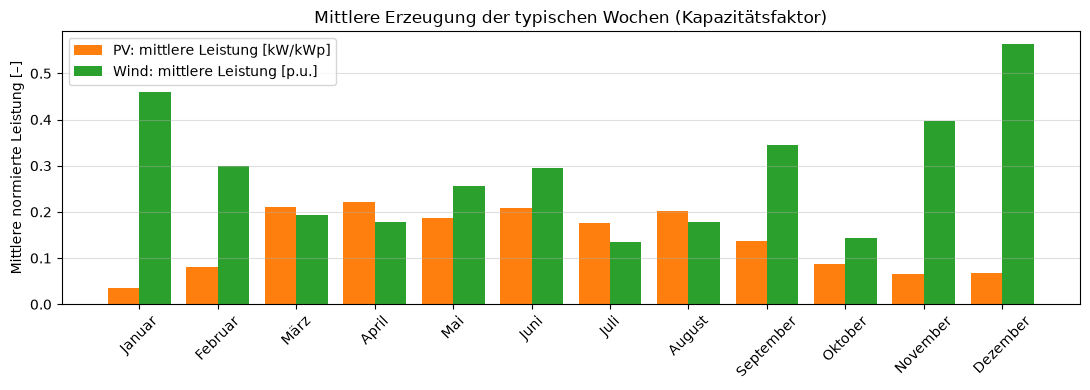

In [45]:
wt.plot_monthly_overview(WEATHER)
plt.show()

### Windenergieanlage (Vestas V90-2.0 MW)

**Anlagendaten** [7]: Nennleistung 2,0 MW, Rotordurchmesser 90 m (überstrichene Fläche A ≈ 6 362 m²), Nabenhöhen 80 / 95 / 105 m, Einschaltgeschwindigkeit 4 m/s, Nenngeschwindigkeit 13 m/s, Abschaltgeschwindigkeit 25 m/s. Verwendet wird eine Nabenhöhe von 105 m.

**Physikalischer Hintergrund:** Die im Wind enthaltene Leistung, die durch die Rotorfläche strömt, ist

P_Wind = ½ · ρ · A · v³

mit der Luftdichte ρ ≈ 1,225 kg/m³. Eine Windenergieanlage kann davon nur den Anteil c_p (Leistungsbeiwert) entnehmen; theoretisch höchstens c_p,Betz = 16/27 ≈ 0,59 [9]. Real erreichte Werte und die Regelung der Anlage sind in der **Leistungskennlinie** P(v) zusammengefasst, die der Hersteller für eine Standard-Luftdichte angibt. Sie hat vier Bereiche [9]:

| Bereich | Windgeschwindigkeit | Leistung |
|---|---|---|
| Stillstand | v < v_ein | 0 |
| Teillast | v_ein ≤ v < v_Nenn | steigt etwa mit v³ |
| Volllast | v_Nenn ≤ v < v_ab | Nennleistung (Pitch-Regelung begrenzt die Leistung) |
| Sturmabschaltung | v ≥ v_ab = 25 m/s | 0 |

**Kennlinie:** Die Stützstellen (Schrittweite 0,5 m/s) stammen aus der Turbinendatenbank der Open Energy Database (OEDB), die mit der Python-Bibliothek *windpowerlib* ausgeliefert wird; als Quelle ist dort die oben genannte Herstellerangabe auf wind-turbine-models.com eingetragen [8]. Zwischen den Stützstellen wird linear interpoliert. Die Tabelle beginnt bereits bei 3,5 m/s mit 42 kW, während [7] eine Einschaltgeschwindigkeit von 4 m/s nennt. Oberhalb von 12,5 m/s wird die Nennleistung von 2 000 kW angesetzt.

**Höhenumrechnung:** Die Windgeschwindigkeit nimmt mit der Höhe zu. Die API liefert sie in 100 m Höhe; auf die Nabenhöhe h wird mit dem Potenzgesetz umgerechnet [9]:

v_Nabe = v_100 · (h / 100 m)^α, &nbsp; α = 1/7

Bei h = 105 m ergibt sich ein Faktor von 1,007. Der Einfluss ist also gering.

**Vereinfachungen:** keine Korrektur der Luftdichte (Temperatur, Höhe), keine Verfügbarkeitsverluste, keine Abschattung durch andere Anlagen, Stundenwerte statt Böen.

**Normierung:** Neben der Leistung in kW wird die Leistung bezogen auf die Nennleistung gespeichert (`wind_pu`). Damit lässt sich die Zeitreihe auch auf andere Anlagengrößen übertragen. Wie die 2-MW-Anlage in das Netz eingebunden wird, wird in Aufgabe 4 festgelegt (Anschluss an die Mittelspannung oder skalierte Anlage im Niederspannungsnetz).

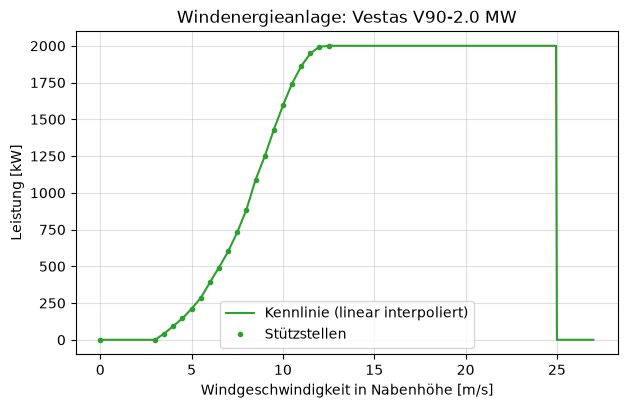

In [46]:
wt.plot_wind_curve()
plt.show()

### PV-Anlage (Trina Solar Vertex S+ 460 W)

**Moduldaten:** Trina Solar Vertex S+ TSM-NEG9RC.27, bifaziales Glas-Glas-Modul (n-Typ, i-TOPCon), 144 Halbzellen, 1762 × 1134 mm (2,0 m²).

| Kenngröße | Wert | Quelle |
|---|---|---|
| Nennleistung P_STC (1000 W/m², 25 °C Zelltemperatur) | 460 W | [10] |
| Modulwirkungsgrad | 23,0 % | [10] |
| Temperaturkoeffizient von P_max (γ) | −0,29 %/K | [11] |
| NOCT (800 W/m², 20 °C Luft, 1 m/s Wind) | 43 °C | [11] |

Das Datenblatt [11] listet die Leistungsklassen 425–450 W; die Temperaturkennwerte gelten für die gesamte Modellfamilie und werden für die 460-W-Klasse übernommen.

**Umrechnung Einstrahlung → Leistung:**

1. *Einstrahlung auf die Modulebene:* Die API liefert direkt die Globalstrahlung auf die geneigte Fläche G (35°, Süd), sodass keine eigene Umrechnung von horizontaler auf geneigte Fläche nötig ist [6].
2. *Zelltemperatur* nach dem NOCT-Modell [12]:

   T_Zelle = T_Luft + (NOCT − 20 °C) / (800 W/m²) · G

3. *Leistung:* Die Modulleistung ist näherungsweise proportional zur Einstrahlung und nimmt mit steigender Zelltemperatur linear ab [12]:

   P_AC = P_STC · (G / 1000 W/m²) · [1 + γ · (T_Zelle − 25 °C)] · η_System

   mit η_System = 0,86 für Verluste in Wechselrichter, Leitungen, durch Verschmutzung und Fehlanpassung (Annahme; die Temperaturverluste sind bereits im Term mit γ enthalten).

**Beispiel:** Bei G = 1000 W/m² und 25 °C Lufttemperatur ist T_Zelle ≈ 53,8 °C und P_AC ≈ 363 W je Modul (0,79 kW/kWp).

**Vereinfachungen:** kein bifazialer Mehrertrag von der Rückseite, keine Verschattung, kein verändertes Verhalten bei schwacher Einstrahlung, keine Leistungsbegrenzung durch den Wechselrichter.

**Normierung:** Die Leistung wird je Modul (`pv_module_w`) und je kWp installierter Leistung (`pv_kw_per_kwp`) gespeichert. Eine Anlage mit z. B. 22 Modulen hat 22 × 0,46 kW = 10,12 kWp; ihre Leistung ist `pv_kw_per_kwp` × 10,12 kW.

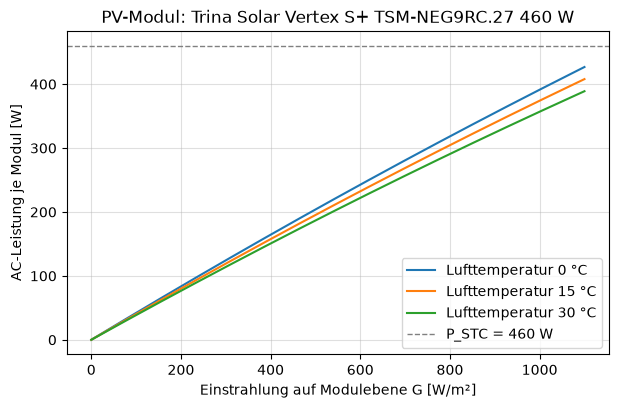

In [47]:
wt.plot_pv_curve()
plt.show()

### Beispiel: typische Woche im Juli

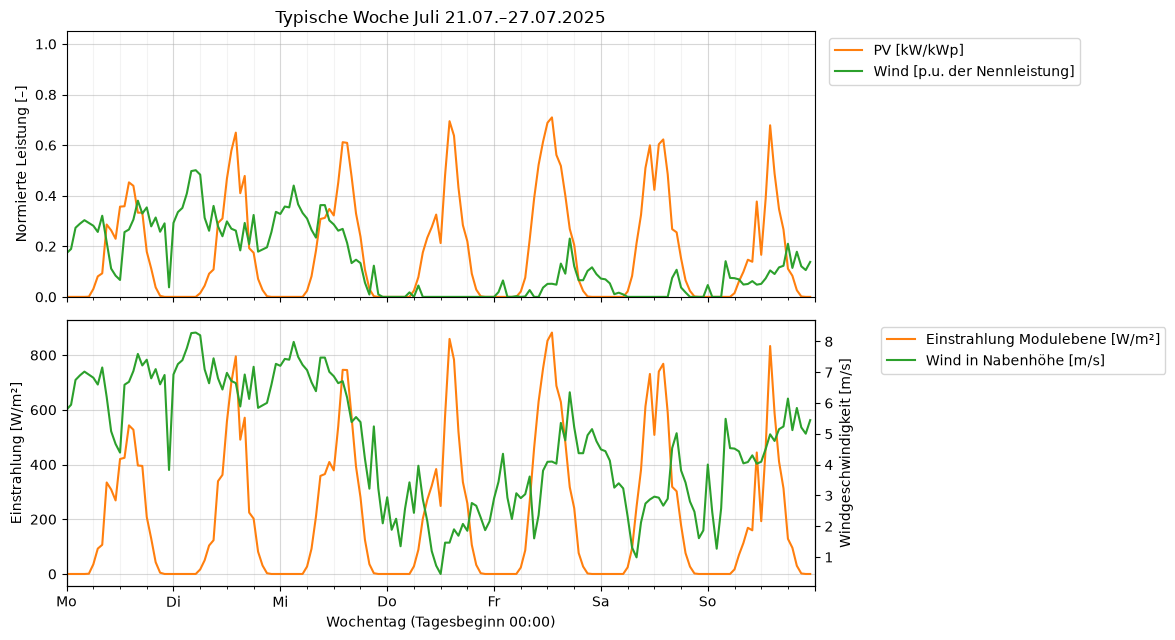

In [48]:
wt.plot_weather_week(WEATHER, Month.JULY)
plt.show()

### Quellen zu Profilen und Daten

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025, S. 3–4. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[2] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Repräsentative Profile BDEW H25, G25, L25, P25, S25 – Veröffentlichung“, Datensatz (CSV, Profil Haushalte), Berlin, 2025.

[3] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Anwendung der Repräsentativen VDEW-Lastprofile step-by-step“, Berlin, 2000, S. 18 f. Online: https://www.bdew.de/media/documents/2000131_Anwendung-repraesentativen_Lastprofile-Step-by-step.pdf

[4] P. Zippenfenig, „Open-Meteo.com Weather API“, Zenodo, 2023, doi: 10.5281/ZENODO.7970649.

[5] H. Hersbach et al., „The ERA5 global reanalysis“, Quarterly Journal of the Royal Meteorological Society, Bd. 146, Nr. 730, S. 1999–2049, 2020, doi: 10.1002/qj.3803.

[6] Open-Meteo, „Historical Weather API – Documentation“. Online: https://open-meteo.com/en/docs/historical-weather-api (Abruf: 14.10.2026).

[7] wind-turbine-models.com, „Vestas V90“. Online: https://www.wind-turbine-models.com/turbines/16-vestas-v90 (Abruf: 14.10.2026).

[8] windpowerlib, Version 0.2.2, Turbinendatenbank der Open Energy Database (Datei `oedb/power_curves.csv`, Eintrag „V90/2000“). Online: https://github.com/wind-python/windpowerlib

[9] E. Hau, *Windkraftanlagen: Grundlagen, Technik, Einsatz, Wirtschaftlichkeit*, 6. Aufl. Berlin, Heidelberg: Springer Vieweg, 2016.

[10] Trina Solar, „Vertex S+ NEG9RC.27“, Produktseite. Online: https://www.trinasolar.com/de/NEG9RC.27/ (Abruf: 14.10.2026).

[11] Trina Solar, „Vertex S+ – Bifaziales Doppelglas N-Typ i-TOPCon Modul, TSM-NEG9RC.27“, Datenblatt, Version TSM_DE_2024_B, 2024. Online: https://www-cdn.trinasolar.com/wwwstorage/sites/8/250227_Datasheet_VertexS_NEG9RC.27_DE_2024_B_web.pdf

[12] J. A. Duffie und W. A. Beckman, *Solar Engineering of Thermal Processes*, 4. Aufl. Hoboken, NJ: Wiley, 2013.

*Bei [3], [9] und [12] die verwendeten Seiten bzw. Kapitel anhand der eigenen Ausgabe ergänzen bzw. prüfen.*

## Aufgabe 3 – Saisonale Erzeugungs- und Lastprofile

In dieser Aufgabe werden aus den aufbereiteten Profilen (Abschnitt *Profile und Datengrundlagen*) die Zeitreihen für alle Lasten und Erzeugungsanlagen des Ortsnetzes erzeugt, skaliert, geprüft und den Netzelementen zugeordnet. Die eigentliche Lastflussrechnung folgt in Aufgabe 4.

**Betrachtete Zeiträume:** 12 typische Wochen (je Monat eine, Montag bis Sonntag) des Jahres 2025 in Stundenauflösung, also 12 × 168 = 2016 Zeitschritte. Die vier Jahreszeiten werden über je drei Monate abgebildet.

### 3.1 Festlegungen

| Größe | Wert | Begründung |
|---|---|---|
| Jahresverbrauch je Haushalt | 3 500 kWh/a | typischer Verbrauch eines Haushalts mit 2–3 Personen *(Quelle ergänzen, z. B. Stromspiegel für Deutschland)* |
| Leistungsfaktor der Haushalte | cos φ = 0,97 induktiv | Haushaltslasten sind überwiegend ohmsch mit geringem induktivem Anteil (Annahme) |
| Anteil Haushalte mit PV | 50 % | Szenario mit deutlicher PV-Durchdringung; zum Vergleich in Aufgabe 4 zusätzlich 100 % |
| PV-Anlage je Haushalt | 22 Module × 460 W = 10,12 kWp | übliche Größe einer Dachanlage auf einem Einfamilienhaus |
| Leistungsfaktor PV und Wind | cos φ = 1 | Vereinfachung: keine Blindleistungsbereitstellung |
| Windenergieanlage | 1 × Vestas V90-2.0 MW | Anschluss in der Mittelspannung an Bus 1 (siehe Aufgabe 4) |

**Vorzeichen und Einheiten:** Alle Leistungen werden in pandapower in MW bzw. Mvar angegeben. Lasten (`load`) verwenden das Verbraucherzählpfeilsystem (P > 0: Bezug), Erzeugungsanlagen (`sgen`) das Erzeugerzählpfeilsystem (P > 0: Einspeisung). Die Blindleistung der Haushalte ergibt sich aus Q = P · tan(arccos 0,97) = 0,25 · P.

**Hinweis zum Lastprofil:** Das Standardlastprofil beschreibt das mittlere Verhalten vieler Haushalte. Es wird für jeden der Haushalte gleich verwendet. Einzelne Lastspitzen (z. B. Kochen, Durchlauferhitzer) sind darin nicht enthalten, die Gleichzeitigkeit ist bereits berücksichtigt.

In [49]:
ANNUAL_KWH   = 3500          # Jahresverbrauch je Haushalt [kWh/a]
COS_PHI_LOAD = 0.97          # Leistungsfaktor Haushalte (induktiv)
PV_SHARE     = 0.5           # Anteil der Haushalte mit PV-Anlage
PV_MODULES   = 22            # Module je Anlage
PV_KWP       = PV_MODULES * wt.PV_MODULE["p_stc_w"] / 1000      # installierte Leistung je Anlage [kWp]
MV_LINE_KM   = 5.0           # Länge der MS-Leitung Umspannwerk -> Ortsnetzstation [km]

print(f"PV-Anlage: {PV_MODULES} × {wt.PV_MODULE['p_stc_w']:.0f} W = {PV_KWP:.2f} kWp")

PV-Anlage: 22 × 460 W = 10.12 kWp


### 3.2 Zeitreihen erzeugen

Für jeden Monat wird die Lastwoche auf dieselben Kalendertage gelegt wie die Wetterwoche (`start` = Montag der Wetterwoche). Dadurch passen Zeitstempel, Last und Erzeugung in jedem Zeitschritt zusammen. Je Zeitschritt entstehen:

- `p_hh_mw`, `q_hh_mvar`: Wirk- und Blindleistung **je Haushalt** (H25, dynamisiert, skaliert auf 3 500 kWh/a)
- `pv_mw_per_kwp`: PV-Leistung **je kWp** (aus Einstrahlung und Temperatur)
- `wind_mw`: Leistung der Windenergieanlage (aus der Windgeschwindigkeit in Nabenhöhe)

In [50]:
TS = sim.build_timeseries(PROFILES, WEATHER, annual_kwh=ANNUAL_KWH, cos_phi_load=COS_PHI_LOAD)
TS.head()

,month,hour_of_week,p_hh_mw,pv_mw_per_kwp,wind_mw,q_hh_mvar
time,,,,,,
2025-01-06 00:00:00,JANUARY,0,0.000325,0.0,1.977820,0.000081
2025-01-06 01:00:00,JANUARY,1,0.000279,0.0,1.994902,0.000070
2025-01-06 02:00:00,JANUARY,2,0.000264,0.0,1.964563,0.000066
2025-01-06 03:00:00,JANUARY,3,0.000262,0.0,1.921745,0.000066
2025-01-06 04:00:00,JANUARY,4,0.000273,0.0,1.971874,0.000069


### 3.3 Netzelemente und Zuordnung

Die Zeitreihen werden an die Elemente des Ortsnetzes gebunden, das in Aufgabe 4 beschrieben wird: 58 Haushalte (57 aus dem Kerber-Dorfnetz und die bestehende Last an Bus 3), PV-Anlagen an der Hälfte der Hausanschlüsse und die Windenergieanlage an Bus 1. Jeder PV-Anlage ist der Haushalt zugeordnet, an dessen Bus sie angeschlossen ist. Die PV-Anlagen werden in jedem Abgang gleichmäßig über die Länge verteilt, damit die Auswahl reproduzierbar ist und nicht zufällig einen Abgang bevorzugt.

In [51]:
NET, IDX, HOUSEHOLDS = on.build_ortsnetz(with_mv_line=True, mv_line_km=MV_LINE_KM)
HAS_PV = on.assign_pv(HOUSEHOLDS, share=PV_SHARE)
PV = on.add_pv_systems(NET, HOUSEHOLDS, HAS_PV, kwp=PV_KWP)

ELEMENTS = sim.element_table(HOUSEHOLDS, PV, IDX, ANNUAL_KWH, COS_PHI_LOAD)
print(f"{len(HOUSEHOLDS)} Haushalte, {len(PV)} PV-Anlagen ({PV.kwp.sum():.1f} kWp), 1 Windenergieanlage")
ELEMENTS.groupby("Profil").agg(Anzahl=("Index", "size"), Skalierung=("Skalierung", "first"))

58 Haushalte, 28 PV-Anlagen (283.4 kWp), 1 Windenergieanlage


,Anzahl,Skalierung
Profil,,
H25 Haushalt,58,"3500 kWh/a, cos φ = 0.97"
PV (Wetter),28,"10.12 kWp, cos φ = 1"
Wind (Wetter),1,"1 × V90-2.0 MW, cos φ = 1"


In [52]:
ELEMENTS.head(10)

,Element,Index,Bus,Name,Profil,Skalierung
0,load,0,2,Load,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
1,load,1,4,HH 1-1,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
2,load,2,6,HH 1-2,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
3,load,3,8,HH 1-3,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
4,load,4,10,HH 1-4,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
5,load,5,12,HH 1-5,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
6,load,6,14,HH 1-6,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
7,load,7,16,HH 1-7,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
8,load,8,18,HH 1-8,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"
9,load,9,20,HH 1-9,H25 Haushalt,"3500 kWh/a, cos φ = 0.97"


**Einbindung je Zeitschritt** (`sim.run_simulation`): Für jeden Zeitschritt t werden die Leistungen der Elemente gesetzt und anschließend der Lastfluss gerechnet:

- jeder Haushalt: `load.p_mw = p_hh_mw(t)`, `load.q_mvar = q_hh_mvar(t)`
- jede PV-Anlage: `sgen.p_mw = pv_mw_per_kwp(t) · kWp`
- Windenergieanlage: `sgen.p_mw = wind_mw(t)`

Das Ausgangsnetz wird dabei kopiert und nicht verändert, sodass jede Simulation reproduzierbar vom selben Netz ausgeht.

### 3.4 Prüfung der Zeitreihen

In [53]:
sim.check_timeseries(TS, HOUSEHOLDS, PV, NET, IDX)

,Prüfung,Ergebnis,Details
0,12 Monate vorhanden,ok,12 Monate
1,je Monat 168 Stunden,ok,168–168 Stunden
2,lückenlose Stundenschritte,ok,
3,jede Woche beginnt montags 00:00,ok,
4,keine fehlenden Werte,ok,
5,Leistungen nicht negativ,ok,
6,jeder Haushalt hat ein load-Element,ok,58 Haushalte
7,jede PV-Anlage hängt am Bus ihres Haushalts,ok,28 PV-Anlagen
8,WEA an Bus 1 (20 kV),ok,


In [54]:
ENERGY = sim.energy_summary(TS, n_households=len(HOUSEHOLDS), total_kwp=PV.kwp.sum())
ENERGY.round(0)

,Last [kWh],PV [kWh],Wind [kWh],Residuallast NS [kWh],Stunden mit PV > Last
Monat,,,,,
Januar,4612.0,1660.0,154745.0,2953.0,23
Februar,4527.0,3813.0,100932.0,714.0,44
März,4156.0,10005.0,64783.0,-5849.0,68
April,3921.0,10550.0,59655.0,-6629.0,74
Mai,3440.0,8909.0,86291.0,-5469.0,79
Juni,3392.0,9876.0,99126.0,-6484.0,85
Juli,3381.0,8352.0,45600.0,-4971.0,85
August,3303.0,9641.0,59598.0,-6338.0,78
September,3394.0,6479.0,116116.0,-3085.0,63


### 3.5 Darstellung vor der Netzeinbindung

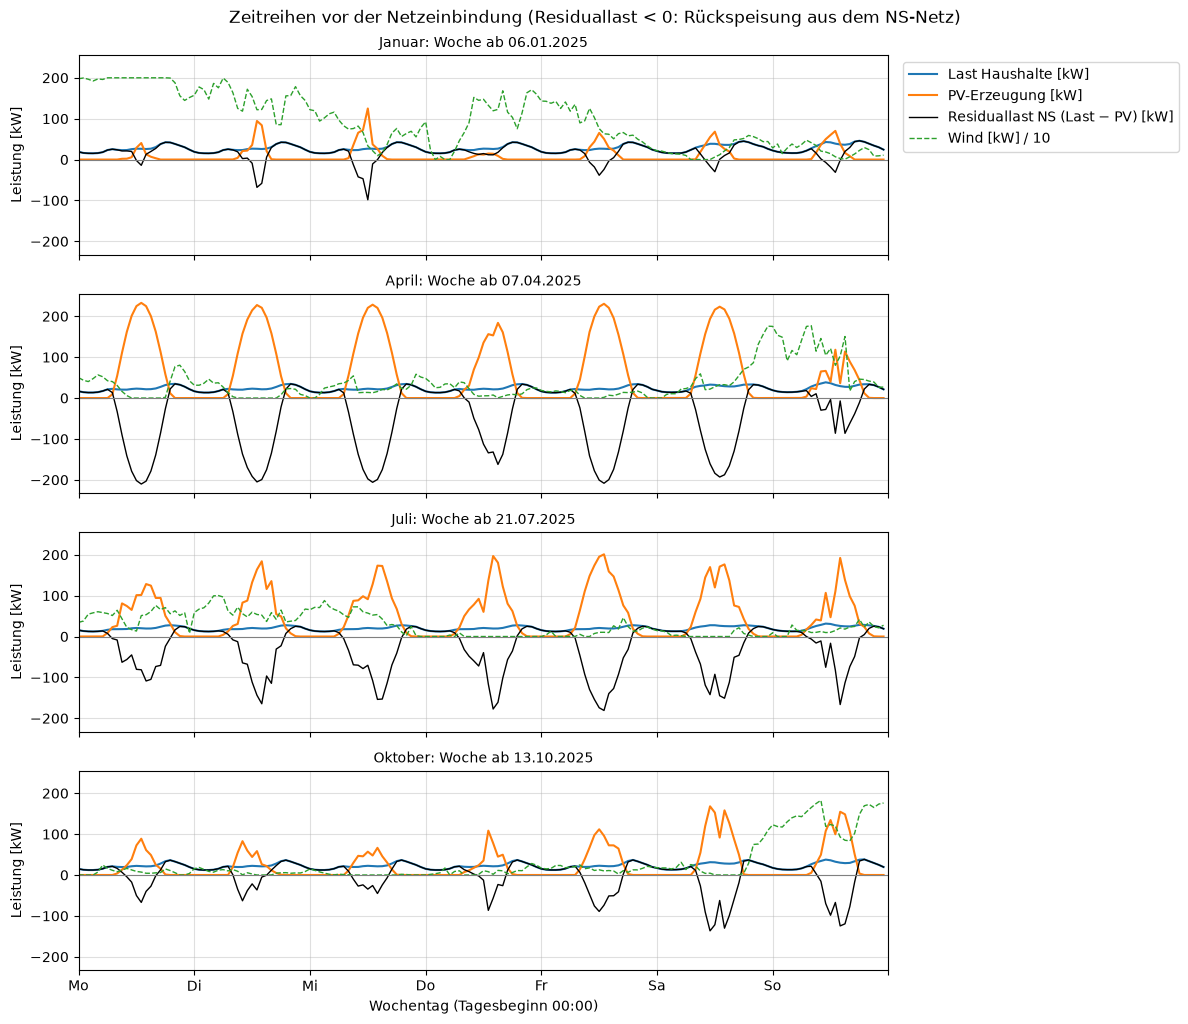

In [55]:
sim.plot_timeseries(TS, n_households=len(HOUSEHOLDS), total_kwp=PV.kwp.sum())
plt.show()

### Auswertung Aufgabe 3

*Nach dem Ausführen mit den echten Wetterdaten ergänzen, z. B.:*

- Wie unterscheidet sich der Wochenverbrauch zwischen Winter und Sommer (Dynamisierung)?
- In welchen Monaten übersteigt die PV-Erzeugung den Verbrauch über die Woche gesehen (negative Residuallast), und in wie vielen Stunden je Woche wird aus dem NS-Netz zurückgespeist?
- Wie verhalten sich PV (Sommermaximum) und Wind (Wintermaximum) zueinander?

## Aufgabe 4 – Ortsnetz und saisonale Simulation

### 4.1 Netzstruktur

Als Ortsnetz wird das **Dorfnetz nach Kerber** verwendet [13]. Kerber hat aus der Auswertung realer Niederspannungsnetze typische Netzstrukturen für ländliche Gebiete, Dörfer und Vorstädte abgeleitet; die Netze sind in pandapower hinterlegt [15]. Das Dorfnetz passt zum bestehenden Netz, weil es mit einem Transformator derselben Bemessungsleistung (0,4 MVA) versorgt wird.

**Einbindung in das bestehende Netz** (die bestehende Topologie bleibt erhalten):

- unverändert: externes Netz, Bus 1 (20 kV), Transformator 0,4 MVA 20/0,4 kV mit Stufenschalter, Bus 2 (NS-Sammelschiene), Leitung zu Bus 3 mit Last
- übernommen aus [13]: sechs Abgänge mit 57 Hausanschlüssen an Bus 2. Kerbers Sammelschiene wird durch Bus 2 ersetzt, seine 10-kV-Seite und sein Transformator entfallen.
- neu: MS-Leitung zwischen einem Umspannwerk und Bus 1, Windenergieanlage an Bus 1 (siehe 4.3)
- jede Leitung erhält an beiden Enden einen Leistungsschalter (Normalzustand geschlossen), wie in Aufgabe 1 festgelegt

Jeder Abgang besteht aus einem Hauptstrang (NAYY 4x150), von dem an jedem Verbindungspunkt (Muffe bzw. Kabelverteiler) eine Hausanschlussleitung (NAYY 4x50, abwechselnd 15 m und 31 m) zu einem Haus abzweigt.

In [56]:
on.describe_network(NET, IDX, HOUSEHOLDS, PV)

,Hausanschlüsse,PV-Anlagen,max. Entfernung [m]
Abgang,,,
Bestand (Bus 3),1,0,100
1,9,4,375
2,9,4,375
3,16,8,495
4,12,6,415
5,7,4,316
6,4,2,287


In [57]:
print(f"Busse: {len(NET.bus)}, Leitungen: {len(NET.line)}, Schalter: {len(NET.switch)}, "
      f"Lasten: {len(NET.load)}, Erzeugungsanlagen: {len(NET.sgen)}")
print(f"Auswertungsbus: {NET.bus.at[IDX['eval_bus'], 'name']} "
      f"({HOUSEHOLDS.distance_m.max():.0f} m Leitungslänge ab NS-Sammelschiene)")

Busse: 118, Leitungen: 116, Schalter: 232, Lasten: 58, Erzeugungsanlagen: 29
Auswertungsbus: D loadbus_3_16 (495 m Leitungslänge ab NS-Sammelschiene)


**Ausgewertete Sammelschiene:** Die Spannung wird am **Hausanschluss mit der größten Entfernung zum Transformator** ausgewertet (Abgang 3, Haus 16, 495 m). Dort wirken die Spannungsänderungen über dem längsten Strang am stärksten: Bei hoher Last ist die Spannung dort am niedrigsten, bei hoher PV-Einspeisung am höchsten. Zusätzlich werden in jedem Zeitschritt die niedrigste und die höchste Spannung aller NS-Busse gespeichert.

### 4.2 Leitungsparameter

| Kabel | Einsatz | R' [Ω/km] | X' [Ω/km] | C' [nF/km] | I_max [A] | Gesamtlänge |
|---|---|---|---|---|---|---|
| NAYY 4x150 | Hauptstränge | 0,2067 | 0,0804 | 830 | 275 | 2,13 km |
| NAYY 4x50 | Hausanschlüsse | 0,6417 | 0,0848 | 670 | 141 | 1,29 km |
| NAYY 4x50 SE | bestehende Leitung zu Bus 3 | 0,642 | 0,083 | 210 | 142 | 0,10 km |
| NA2XS2Y 1x185 RM/25 12/20 kV | MS-Leitung | 0,161 | 0,117 | 273 | 362 | 5,0 km |

Die Werte der NAYY-Kabel stammen aus der Umsetzung der Kerber-Netze in pandapower [13], [15]. Die Wirkwiderstände entsprechen den Höchstwerten für Aluminiumleiter nach DIN EN 60228 (50 mm²: 0,641 Ω/km, 150 mm²: 0,206 Ω/km bei 20 °C) [14]. NAYY ist ein Niederspannungskabel mit Aluminiumleiter (A), PVC-Isolierung und PVC-Mantel (Y), 4 Leiter.

*Hinweis: Die Hausanschlusskabel werden in pandapower zufällig als „NAYY 4x50“ oder „NAYY 4x50 SE“ gewählt. Für reproduzierbare Ergebnisse werden hier alle Hausanschlüsse einheitlich mit NAYY 4x50 modelliert.*

**Umrechnung auf das Modell:** pandapower rechnet die Leitungen mit dem π-Ersatzschaltbild. Die Impedanz eines Abschnitts ergibt sich aus Belag × Länge, z. B. für den Hauptstrang von Abgang 3 (16 Abschnitte à 29 m = 0,464 km):

R = 0,2067 Ω/km · 0,464 km = 0,096 Ω, &nbsp; X = 0,0804 Ω/km · 0,464 km = 0,037 Ω

Das Verhältnis R/X ≈ 2,6 zeigt: Auch der dickere Hauptstrang ist ohmsch dominiert, die Spannung wird im NS-Netz also vor allem durch die Wirkleistung beeinflusst.

In [58]:
(NET.line.groupby("std_type")
    .agg(Anzahl=("length_km", "size"), Gesamtlänge_km=("length_km", "sum"),
         r_ohm_per_km=("r_ohm_per_km", "first"), x_ohm_per_km=("x_ohm_per_km", "first"),
         c_nf_per_km=("c_nf_per_km", "first"), max_i_ka=("max_i_ka", "first"))
    .round(4))

,Anzahl,Gesamtlänge_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka
std_type,,,,,,
NA2XS2Y 1x185 RM/25 12/20 kV,1,5.000,0.1610,0.1170,273.0,0.362
NAYY 4x150,57,2.125,0.2067,0.0804,830.0,0.275
NAYY 4x50,57,1.287,0.6417,0.0848,670.0,0.141
NAYY 4x50 SE,1,0.100,0.6420,0.0830,210.0,0.142


### 4.3 Mittelspannungsanbindung und Windenergieanlage

Die Windenergieanlage hat mit 2 MW das Fünffache der Bemessungsleistung des Ortsnetztransformators und kann deshalb nicht im Niederspannungsnetz angeschlossen werden. Sie wird an Bus 1 (20 kV) angeschlossen.

Im Ausgangsnetz hält das externe Netz die Spannung an Bus 1 starr auf 1,02 pu, eine Einspeisung dort hätte also keine Wirkung auf die Spannung. Deshalb wird das externe Netz an einen neuen Bus „Bus 0 UW“ (Umspannwerk) verlegt und über eine 5 km lange MS-Kabelleitung (NA2XS2Y 1x185 RM/25 12/20 kV) mit Bus 1 verbunden. So hebt die Einspeisung der Windenergieanlage über den Spannungsfall an der MS-Leitung die Spannung an Bus 1 und damit an der Ortsnetzstation an.

**Vereinfachung:** Weitere Ortsnetzstationen und Verbraucher an der MS-Leitung werden nicht modelliert. In einem realen MS-Netz würden sie einen Teil der Windleistung aufnehmen.

### 4.4 Zeitschrittweise Simulation

Für jeden der 2016 Zeitschritte wird ein AC-Lastfluss (Newton-Raphson) gerechnet. Der Stufenschalter bleibt in der Neutralstellung (`tap_pos = 0`). Konvergiert ein Zeitschritt nicht, wird er mit `converged = False` gekennzeichnet; seine Ergebniswerte bleiben leer und gehen nicht in die Auswertung ein.

Gespeichert werden je Zeitschritt: Spannung am Auswertungsbus, an Bus 1 und Bus 2, niedrigste und höchste Spannung im NS-Netz (mit Bus), Wirkleistung und Auslastung des Transformators, höchste Leitungsauslastung und die Leistung am externen Netz.

In [59]:
RES = sim.run_simulation(NET, IDX, HOUSEHOLDS, PV, TS, tap_pos=0)
print("Alle Zeitschritte konvergiert." if RES["converged"].all()
      else f"Nicht konvergiert: {(~RES['converged']).sum()} Zeitschritte")
RES.head()

2016 Lastflüsse in 89 s, nicht konvergiert: 0
Alle Zeitschritte konvergiert.


,month,hour_of_week,tap_pos,p_load_mw,p_pv_mw,p_wind_mw,converged,vm_eval_pu,vm_bus1_pu,vm_bus2_pu,vm_lv_min_pu,bus_lv_min,vm_lv_max_pu,bus_lv_max,p_trafo_mw,loading_trafo_pct,loading_line_max_pct,p_ext_grid_mw
time,,,,,,,,,,,,,,,,,,
2025-01-06 00:00:00,JANUARY,0,0.0,0.018830,0.0,1.977820,True,1.020813,1.023966,1.022628,1.020813,70,1.022628,1,0.020271,5.077316,15.303924,-1.950179
2025-01-06 01:00:00,JANUARY,1,0.0,0.016187,0.0,1.994902,True,1.021297,1.024005,1.022856,1.021297,70,1.022856,1,0.017621,4.409491,15.456853,-1.969763
2025-01-06 02:00:00,JANUARY,2,0.0,0.015325,0.0,1.964563,True,1.021384,1.023948,1.022859,1.021384,70,1.022859,1,0.016757,4.192128,15.229254,-1.940509
2025-01-06 03:00:00,JANUARY,3,0.0,0.015190,0.0,1.921745,True,1.021323,1.023865,1.022785,1.021323,70,1.022785,1,0.016622,4.158335,14.899488,-1.898142
2025-01-06 04:00:00,JANUARY,4,0.0,0.015855,0.0,1.971874,True,1.021308,1.023961,1.022835,1.021308,70,1.022835,1,0.017289,4.325976,15.281549,-1.947239


### 4.5 Ergebnisse

#### Spannung am Auswertungsbus über die Zeit

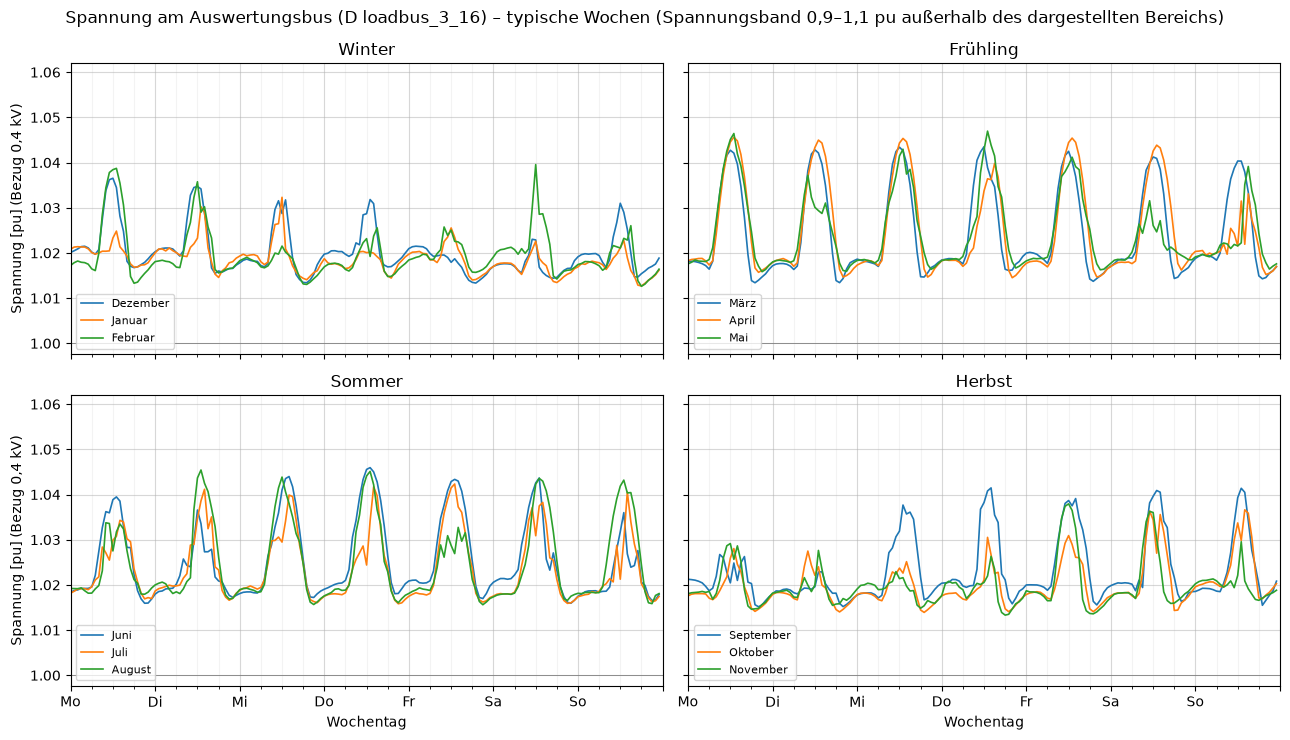

In [60]:
sim.plot_voltage_seasons(RES, column="vm_eval_pu",
                         title=f"Spannung am Auswertungsbus ({NET.bus.at[IDX['eval_bus'], 'name']})")
plt.show()

#### Saisonaler Vergleich

In [61]:
SUMMARY = sim.summary_by_month(RES)
SUMMARY.round(3)

,konvergiert,U_Auswertung min [pu],U_Auswertung max [pu],U_NS min [pu],U_NS max [pu],"Stunden U < 0,9","Stunden U > 1,1",Stunden Rückspeisung,P_Trafo min [kW],Trafo max [%],Leitung max [%]
Monat,,,,,,,,,,,
Januar,168/168,1.013,1.032,1.013,1.032,0,0,22,-96.194,23.980,15.728
Februar,168/168,1.013,1.040,1.013,1.040,0,0,43,-151.433,37.521,22.554
März,168/168,1.013,1.044,1.013,1.044,0,0,68,-186.434,46.089,27.649
April,168/168,1.015,1.046,1.015,1.046,0,0,74,-205.817,50.851,30.474
Mai,168/168,1.016,1.047,1.016,1.047,0,0,76,-211.807,52.313,31.332
Juni,168/168,1.016,1.046,1.016,1.046,0,0,84,-200.189,49.415,29.608
Juli,168/168,1.016,1.042,1.016,1.042,0,0,84,-177.172,43.808,26.274
August,168/168,1.016,1.045,1.016,1.045,0,0,74,-198.044,48.916,29.309
September,168/168,1.015,1.041,1.015,1.041,0,0,63,-169.454,41.934,25.203


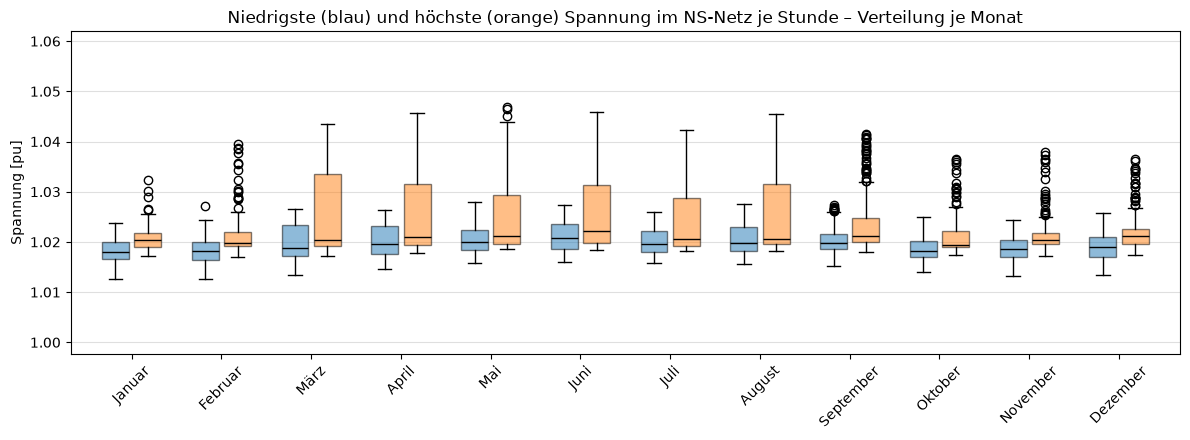

In [62]:
sim.plot_voltage_boxplot(RES)
plt.show()

#### Extremwerte

In [63]:
EXTREMES = sim.extreme_values(RES, NET)
EXTREMES.round(3).T

Ereignis,niedrigste Spannung im NS-Netz,höchste Spannung im NS-Netz,größte Rückspeisung über den Trafo,größter Bezug über den Trafo
Zeitpunkt,Sun 09.02.2025 18:00,Thu 22.05.2025 13:00,Mon 19.05.2025 13:00,Sun 12.01.2025 18:00
U_min [pu],1.013,1.028,1.027,1.013
an Bus,D loadbus_3_16,Bus 3,Bus 3,D loadbus_3_16
U_max [pu],1.017,1.047,1.046,1.017
an Bus,Bus 2,D loadbus_3_16,D loadbus_3_16,Bus 2
U_Auswertung [pu],1.013,1.047,1.046,1.013
P_Trafo [kW],46.937,-203.208,-211.807,47.532
Last [kW],45.377,19.926,20.129,45.968
PV [kW],0.0,227.566,236.634,0.0


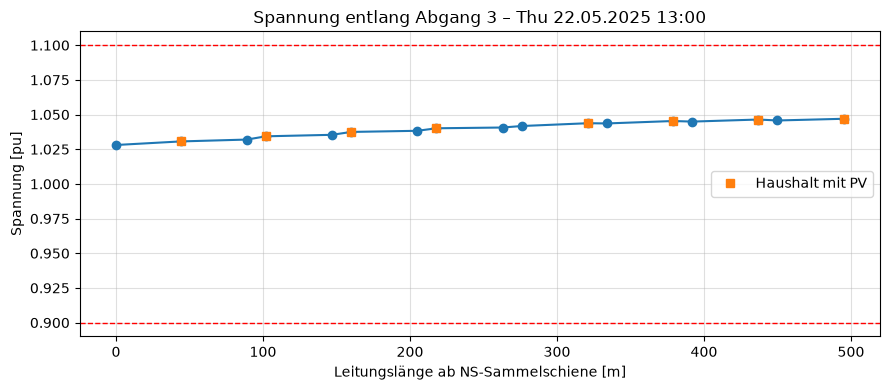

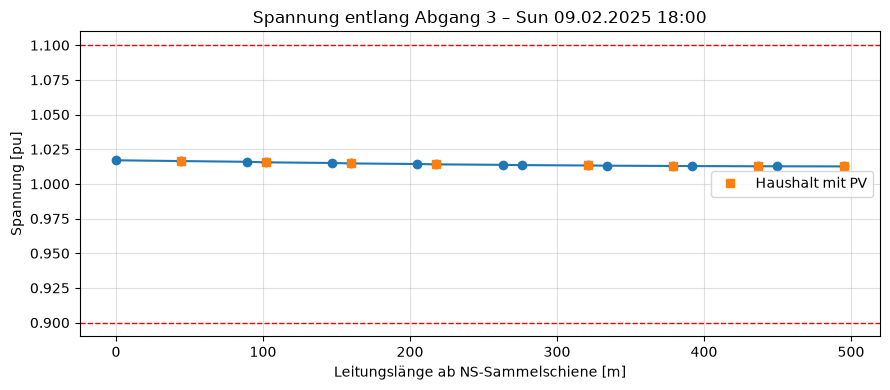

In [64]:
t_max = RES["vm_lv_max_pu"].idxmax()
t_min = RES["vm_lv_min_pu"].idxmin()
sim.plot_voltage_profile(NET, IDX, HOUSEHOLDS, PV, TS, t_max)
sim.plot_voltage_profile(NET, IDX, HOUSEHOLDS, PV, TS, t_min)
plt.show()

#### Leistungsfluss über den Transformator und Rückspeisung

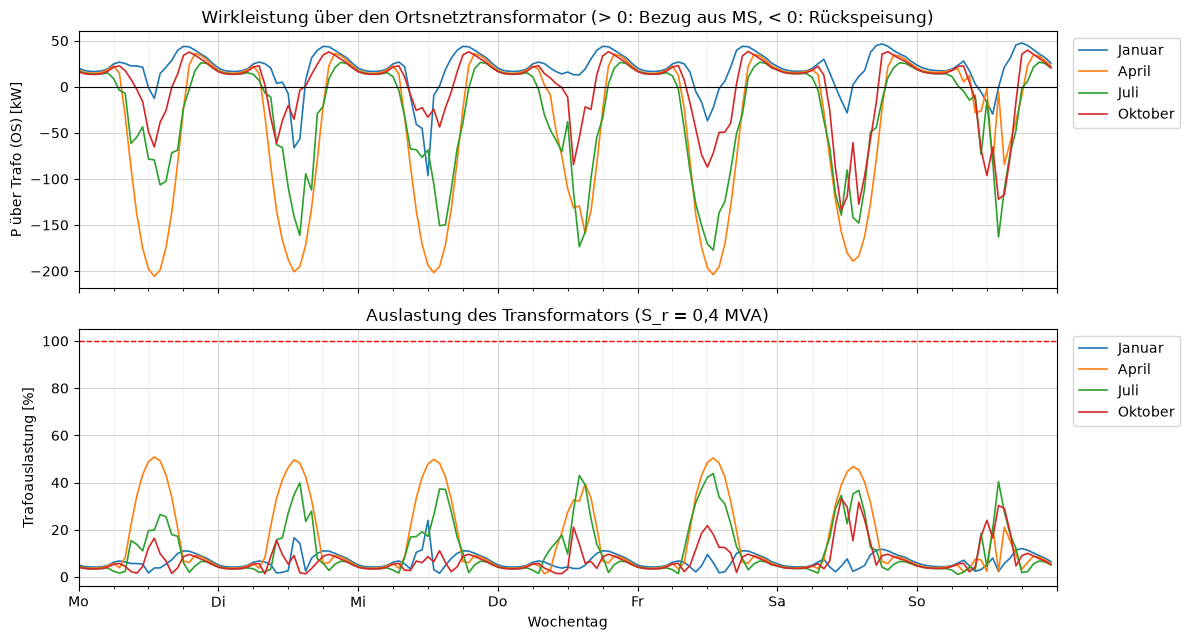

In [65]:
sim.plot_trafo_power(RES)
plt.show()

#### Einfluss der Windenergieanlage auf die Spannung an der Ortsnetzstation

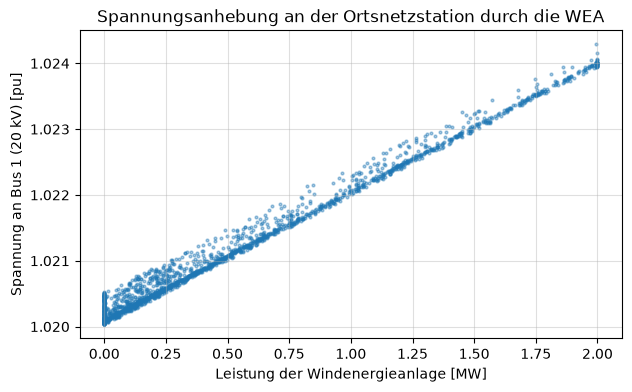

In [66]:
fig, ax = plt.subplots(figsize=(7, 4))
ok = RES[RES["converged"]]
ax.scatter(ok["p_wind_mw"], ok["vm_bus1_pu"], s=4, alpha=0.4)
ax.set_xlabel("Leistung der Windenergieanlage [MW]")
ax.set_ylabel("Spannung an Bus 1 (20 kV) [pu]")
ax.set_title("Spannungsanhebung an der Ortsnetzstation durch die WEA")
ax.grid(True, alpha=0.4)
plt.show()

### 4.6 Vergleich: PV-Anteil 50 % und 100 %

Um den Einfluss einer hohen dezentralen Erzeugung zu zeigen, wird dieselbe Simulation mit PV-Anlagen an allen Hausanschlüssen wiederholt. Alle anderen Größen bleiben gleich.

In [67]:
NET_100, IDX_100, HH_100 = on.build_ortsnetz(with_mv_line=True, mv_line_km=MV_LINE_KM)
PV_100 = on.add_pv_systems(NET_100, HH_100, on.assign_pv(HH_100, share=1.0), kwp=PV_KWP)
RES_100 = sim.run_simulation(NET_100, IDX_100, HH_100, PV_100, TS, tap_pos=0)

def kennzahlen(res, pv):
    ok = res[res["converged"]]
    return {
        "installierte PV [kWp]": pv.kwp.sum(),
        "konvergierte Zeitschritte": f"{len(ok)}/{len(res)}",
        "U_NS min [pu]": ok["vm_lv_min_pu"].min(),
        "U_NS max [pu]": ok["vm_lv_max_pu"].max(),
        "U_Auswertung max [pu]": ok["vm_eval_pu"].max(),
        "Stunden U > 1,1 pu": int((ok["vm_lv_max_pu"] > sim.V_MAX).sum()),
        "Stunden mit Rückspeisung": int((ok["p_trafo_mw"] < 0).sum()),
        "max. Rückspeisung [kW]": -ok["p_trafo_mw"].min() * 1000,
        "max. Trafoauslastung [%]": ok["loading_trafo_pct"].max(),
        "max. Leitungsauslastung [%]": ok["loading_line_max_pct"].max(),
    }

pd.DataFrame({"PV 50 %": kennzahlen(RES, PV), "PV 100 %": kennzahlen(RES_100, PV_100)})

2016 Lastflüsse in 109 s, nicht konvergiert: 0


,PV 50 %,PV 100 %
installierte PV [kWp],283.36,586.96
konvergierte Zeitschritte,2016/2016,2016/2016
U_NS min [pu],1.012619,1.012619
U_NS max [pu],1.046957,1.073114
U_Auswertung max [pu],1.046957,1.073114
"Stunden U > 1,1 pu",0,0
Stunden mit Rückspeisung,706,838
max. Rückspeisung [kW],211.807388,453.963373
max. Trafoauslastung [%],52.313329,111.871285
max. Leitungsauslastung [%],31.331753,64.16157


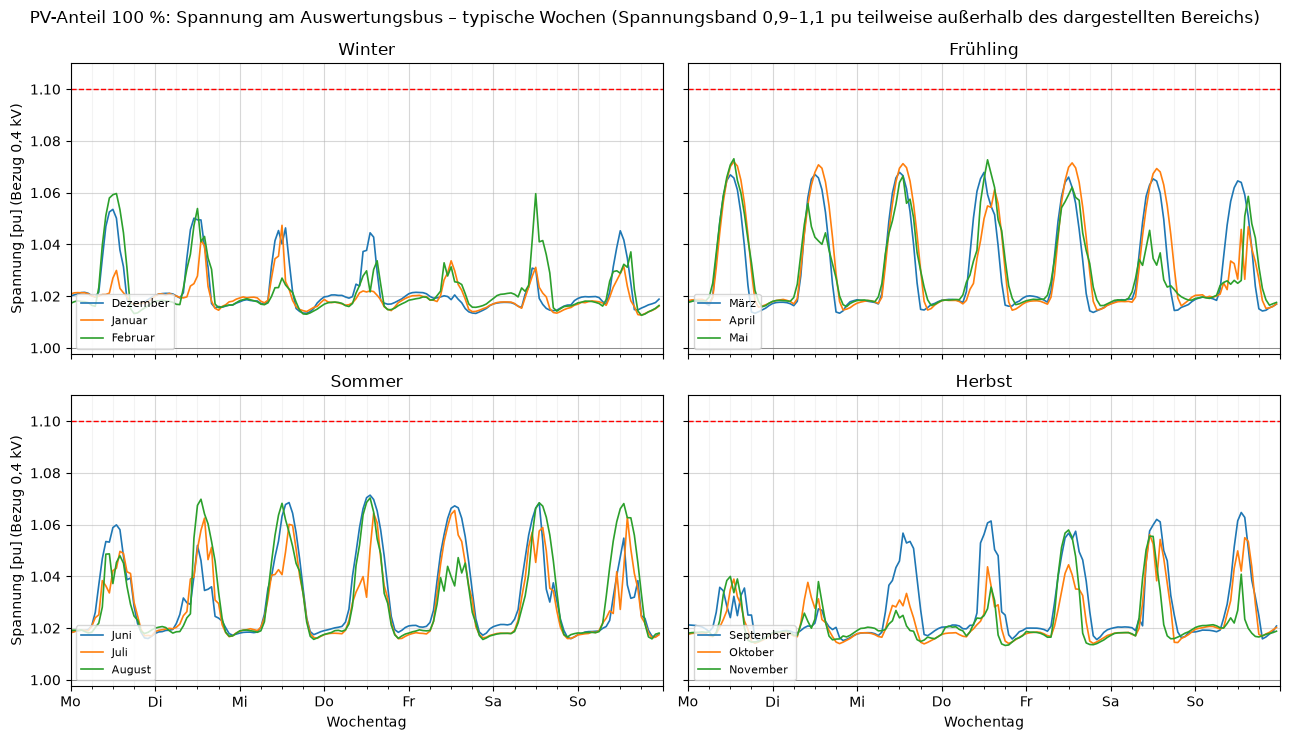

In [68]:
sim.plot_voltage_seasons(RES_100, column="vm_eval_pu", title="PV-Anteil 100 %: Spannung am Auswertungsbus")
plt.show()

### 4.7 Diskussion

In [69]:
ok = RES[RES["converged"]]
print(f"Spannung im NS-Netz: {ok['vm_lv_min_pu'].min():.3f} ... {ok['vm_lv_max_pu'].max():.3f} pu")
print(f"Spannung am Auswertungsbus: {ok['vm_eval_pu'].min():.3f} ... {ok['vm_eval_pu'].max():.3f} pu")
print(f"Stunden außerhalb 0,9 ... 1,1 pu: {int(((ok['vm_lv_min_pu'] < sim.V_MIN) | (ok['vm_lv_max_pu'] > sim.V_MAX)).sum())}")
print(f"Rückspeisung über den Trafo in {int((ok['p_trafo_mw'] < 0).sum())} von {len(ok)} Stunden, "
      f"maximal {-ok['p_trafo_mw'].min() * 1000:.0f} kW")
summer = ok[ok['month'].isin([m.name for m in Season.SUMMER.months])]
winter = ok[ok['month'].isin([m.name for m in Season.WINTER.months])]
print(f"Sommer: U_Auswertung {summer['vm_eval_pu'].min():.3f} ... {summer['vm_eval_pu'].max():.3f} pu")
print(f"Winter: U_Auswertung {winter['vm_eval_pu'].min():.3f} ... {winter['vm_eval_pu'].max():.3f} pu")

Spannung im NS-Netz: 1.013 ... 1.047 pu
Spannung am Auswertungsbus: 1.013 ... 1.047 pu
Stunden außerhalb 0,9 ... 1,1 pu: 0
Rückspeisung über den Trafo in 706 von 2016 Stunden, maximal 212 kW
Sommer: U_Auswertung 1.016 ... 1.046 pu
Winter: U_Auswertung 1.013 ... 1.040 pu


**Mechanismen** (unabhängig von den konkreten Zahlen):

- **Spannungsabsenkung bei Last:** Ohne PV-Einspeisung fließt die Leistung vom Transformator zu den Häusern. Über dem ohmsch dominierten Kabel entsteht ein Spannungsfall ΔU ≈ (R·P + X·Q)/U, der mit der Entfernung zum Transformator zunimmt. Am stärksten ist er an Winterabenden, wenn der Verbrauch hoch ist und keine PV-Erzeugung vorliegt.
- **Spannungsanhebung bei Rückspeisung:** Übersteigt die PV-Erzeugung den Verbrauch, kehrt sich die Flussrichtung um. Der Spannungsfall wird zur Spannungsanhebung, und die Spannung steigt zum Ende des Abgangs hin an. Am stärksten ist das an sonnigen Sommer- und Frühlingsmittagen, vor allem am Wochenende bei geringer Last.
- **Rückspeisung:** Ist die Wirkleistung am Transformator negativ, speist das Ortsnetz in das Mittelspannungsnetz zurück. Die Auslastung des Transformators wird dann durch die Erzeugung und nicht mehr durch die Last bestimmt.
- **Windenergieanlage:** Sie hebt die Spannung an Bus 1 an und verschiebt damit das Spannungsniveau des gesamten Ortsnetzes nach oben. Weil sie vor allem im Winter einspeist, wirkt sie teilweise der lastbedingten Absenkung entgegen, im Frühjahr kann sie zusammen mit PV die Anhebung verstärken.
- **Ausgangsniveau:** Das externe Netz liegt mit 1,02 pu bereits über der Nennspannung. Spannungsabsenkungen haben dadurch mehr Reserve bis zur unteren Grenze, Anhebungen weniger bis zur oberen Grenze.

**Bewertung:** *Nach dem Ausführen ergänzen:* Wird das Spannungsband 0,9–1,1 pu nach DIN EN 50160 [16] eingehalten? Für Erzeugungsanlagen am Niederspannungsnetz gilt zusätzlich, dass die durch sie verursachte Spannungsanhebung begrenzt ist (Richtwert 3 % nach VDE-AR-N 4105 [17]); vergleiche dazu die Spannung am Auswertungsbus mit und ohne PV-Einspeisung. Wie ändert sich das Bild bei 100 % PV?

**Grenzen des Modells:**

- Standardlastprofil statt individueller Lastgänge: Einzelne Lastspitzen fehlen, die Spannungsabsenkung wird eher unterschätzt.
- Stundenmittelwerte: kurzzeitige Spitzen von Last und Erzeugung (z. B. Wolkendurchgang) werden geglättet.
- symmetrischer Drehstrom-Lastfluss: einphasig angeschlossene Lasten und PV-Anlagen führen in realen Netzen zu Unsymmetrie und höheren Spannungsabweichungen einzelner Phasen.
- MS-Netz stark vereinfacht (eine Leitung, keine weiteren Stationen), externe Spannung fest 1,02 pu.
- keine Blindleistungsregelung der Erzeugungsanlagen, Stufenschalter fest in Neutralstellung (Regelung folgt in Aufgabe 5).

### Quellen zu Aufgabe 4

[13] G. Kerber, „Aufnahmefähigkeit von Niederspannungsverteilnetzen für die Einspeisung aus Photovoltaikkleinanlagen“, Dissertation, Technische Universität München, 2011.

[14] DIN EN 60228 (VDE 0295), „Leiter für Kabel und isolierte Leitungen“. Berlin: Beuth/VDE Verlag.

[15] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

[16] DIN EN 50160, „Merkmale der Spannung in öffentlichen Elektrizitätsversorgungsnetzen“. Berlin: Beuth.

[17] VDE-AR-N 4105, „Erzeugungsanlagen am Niederspannungsnetz – Technische Mindestanforderungen für Anschluss und Parallelbetrieb von Erzeugungsanlagen am Niederspannungsnetz“, VDE FNN, 2018.

*Ausgaben und Seiten/Abschnitte anhand der verwendeten Fassung prüfen; für die Kabeldaten zusätzlich ein Herstellerdatenblatt (NAYY, NA2XS2Y) als Primärquelle ergänzen.*